current time: t = 0.003
current time: t = 0.006000001652123778
current time: t = 0.009000008246989604
current time: t = 0.012000023075680979
current time: t = 0.015000049430024797
current time: t = 0.018000090573864716
current time: t = 0.021000116925224407
current time: t = 0.02400013177265752
current time: t = 0.02700013840476774
current time: t = 0.030000140110486552
current time: t = 0.03300014017935115
current time: t = 0.03600014190178259
current time: t = 0.039000148569364304
current time: t = 0.04200016347512097
current time: t = 0.04500018991379794
current time: t = 0.0480002310985984
current time: t = 0.05100025750195288
current time: t = 0.05400027240851562
current time: t = 0.0570002791039626
current time: t = 0.0600002808752698
current time: t = 0.0630002810109918
current time: t = 0.06600028280154113
current time: t = 0.06900028953946824
current time: t = 0.07200030451974218
current time: t = 0.07500033104003224
current time: t = 0.07800037226216198
current time: t = 0.08

MovieWriter ffmpeg unavailable; using Pillow instead.


current time: t = 0.8510163560603217
current time: t = 0.8547087472670357
current time: t = 0.8584109072883254
current time: t = 0.8621228812422552
current time: t = 0.8658447141393197
current time: t = 0.8695764508872523
current time: t = 0.8733181362957115
current time: t = 0.8770698150808477
current time: t = 0.880831531869755
current time: t = 0.884603331204812
current time: t = 0.8883852575479143
current time: t = 0.8921773552846033
current time: t = 0.8959796687280943
current time: t = 0.8997922421232071
current time: t = 0.9036151196502016
current time: t = 0.9074483454285232
current time: t = 0.9112919635204588
current time: t = 0.9151460179347078
current time: t = 0.9190105526298695
current time: t = 0.922885611517851
current time: t = 0.9267712384671966
current time: t = 0.9306674773063419
current time: t = 0.9345743718267956
current time: t = 0.9384919657862489
current time: t = 0.9424203029116179
current time: t = 0.9463594269020184
current time: t = 0.9503093814316761
curr

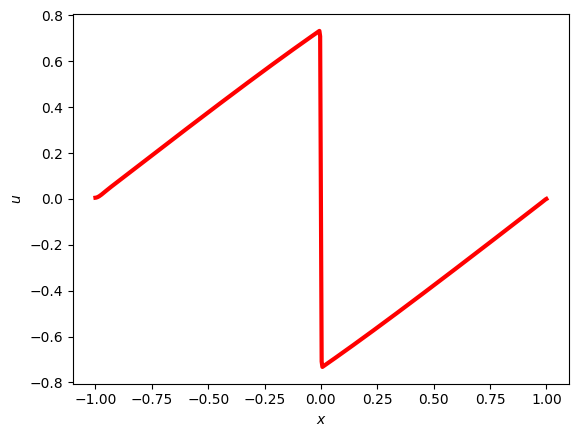

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation

def u0(x):
    return -np.sin(np.pi * x)

def f(u):
    return u ** 2 / 2

def WENO(a, u, dx):
    nx = len(u)
    n_stencil = 3
    I = np.arange(n_stencil-1, nx - n_stencil)

    # Compute the values at the right-hand sides of the cell boundaries (u_{i+1/2}^-) for candidate stencils
    vmm = u[I - 2]
    vm = u[I - 1]
    v = u[I]
    vp = u[I + 1]
    vpp = u[I + 2]

    p0n = (2 * vmm - 7 * vm + 11 * v) / 6
    p1n = (-vm + 5 * v + 2 * vp) / 6
    p2n = (2 * v + 5 * vp - vpp) / 6

    # Compute the weights for candidate stencils
    B0n = 13 / 12 * (vmm - 2 * vm + v) ** 2 + 1 / 4 * (vmm - 4 * vm + 3 * v) ** 2
    B1n = 13 / 12 * (vm - 2 * v + vp) ** 2 + 1 / 4 * (vm - vp) ** 2
    B2n = 13 / 12 * (v - 2 * vp + vpp) ** 2 + 1 / 4 * (3 * v - 4 * vp + vpp) ** 2

    d0n = 1 / 10
    d1n = 6 / 10
    d2n = 3 / 10
    epsilon = 1e-6

    alpha0n = d0n / (epsilon + np.minimum(B0n, 1e30)) ** 2
    alpha1n = d1n / (epsilon + np.minimum(B1n, 1e30)) ** 2
    alpha2n = d2n / (epsilon + np.minimum(B2n, 1e30)) ** 2
    alphasumn = alpha0n + alpha1n + alpha2n

    # ENO stencils weigths
    w0n = alpha0n / alphasumn
    w1n = alpha1n / alphasumn
    w2n = alpha2n / alphasumn

    # Numerical Flux at cell boundary (u_{i+1/2}^{-})
    hn = w0n * p0n + w1n * p1n + w2n * p2n

    # Compute the values at the left-hand side of the cell boundaries (u_{i-1/2}^+)
    vmm = u[I - 1]
    vm = u[I]
    v = u[I + 1]
    vp = u[I + 2]
    vpp = u[I + 3]

    p0p = (-vmm + 5 * vm + 2 * v) / 6
    p1p = (2 * vm + 5 * v - vp) / 6
    p2p = (11 * v - 7 * vp + 2 * vpp) / 6

    B0p = 13 / 12 * (vmm - 2 * vm + v) ** 2 + 1 / 4 * (vmm - 4 * vm + 3 * v) ** 2
    B1p = 13 / 12 * (vm - 2 * v + vp) ** 2 + 1 / 4 * (vm - vp) ** 2
    B2p = 13 / 12 * (v - 2 * vp + vpp) ** 2 + 1 / 4 * (3 * v - 4 * vp + vpp) ** 2

    d0p = 3 / 10
    d1p = 6 / 10
    d2p = 1 / 10
    epsilon = 1e-6

    alpha0p = d0p / (epsilon + np.minimum(B0p, 1e30)) ** 2
    alpha1p = d1p / (epsilon + np.minimum(B1p, 1e30)) ** 2
    alpha2p = d2p / (epsilon + np.minimum(B2p, 1e30)) ** 2
    alphasump = alpha0p + alpha1p + alpha2p

    # ENO stencils weigths
    w0p = alpha0p / alphasump
    w1p = alpha1p / alphasump
    w2p = alpha2p / alphasump

    # Numerical Flux at cell boundary (u_{i-1/2}^{+})
    hp = w0p * p0p + w1p * p1p + w2p * p2p

    LF = np.zeros_like(u)
    res = np.zeros_like(u)

    LF[I] = 0.5 * (f(hn) + f(hp) - abs(a) * (hp - hn)) # Lax-friedrichs flux

    res[I] = (LF[I] - LF[I - 1]) / dx     # L = -df(u) / dx

    return res

if __name__ == "__main__":
    T = 1
    CFL = 0.9
    N = 600
    xl = -1
    xr = 1
    dx = (xr - xl) / N
    nx = N + 1
    x = np.linspace(xl, xr, nx)
    xg = np.concatenate((np.array([xl - 2 * dx, xl - dx]), x, np.array([xr + dx, xr + 2 * dx])))
    nxg = len(xg)

    ut0 = u0(xg)
    lambda0 = max(abs(ut0))
    dt0 = CFL * dx / lambda0
    lbd = lambda0
    dt = dt0
    u = ut0
    t = 0

    res = np.array([])
    res = np.concatenate((res, ut0))
    iter = 0
    while t < T:
        if t + dt > T: dt = T - t
        t = t + dt

        uo = u
        L = WENO(lbd, u, dx)
        u = uo - dt * L

        u[0] = np.interp(xg[0], np.array([xg[2], xg[3], xg[4]]), np.array([u[2], u[3], u[4]]))
        u[1] = np.interp(xg[1], np.array([xg[2], xg[3], xg[4]]), np.array([u[2], u[3], u[4]]))
        u[-1] = np.interp(xg[-1], np.array([xg[nxg-3], xg[nxg-4], xg[nxg-5]]), np.array([u[nxg-3], u[nxg-4], u[nxg-5]]))
        u[-2] = np.interp(xg[-2], np.array([xg[nxg-3], xg[nxg-4], xg[nxg-5]]), np.array([u[nxg-3], u[nxg-4], u[nxg-5]]))


        L = WENO(lbd, u, dx)
        u = 0.75 * uo + 0.25 * (u - dt * L)

        u[0] = np.interp(xg[0], np.array([xg[2], xg[3], xg[4]]), np.array([u[2], u[3], u[4]]))
        u[1] = np.interp(xg[1], np.array([xg[2], xg[3], xg[4]]), np.array([u[2], u[3], u[4]]))
        u[-1] = np.interp(xg[-1], np.array([xg[nxg - 3], xg[nxg - 4], xg[nxg - 5]]),
                          np.array([u[nxg - 3], u[nxg - 4], u[nxg - 5]]))
        u[-2] = np.interp(xg[-2], np.array([xg[nxg - 3], xg[nxg - 4], xg[nxg - 5]]),
                          np.array([u[nxg - 3], u[nxg - 4], u[nxg - 5]]))

        L = WENO(lbd, u, dx)
        u = (uo + 2 * (u - dt * L)) / 3

        u[0] = np.interp(xg[0], np.array([xg[2], xg[3], xg[4]]), np.array([u[2], u[3], u[4]]))
        u[1] = np.interp(xg[1], np.array([xg[2], xg[3], xg[4]]), np.array([u[2], u[3], u[4]]))
        u[-1] = np.interp(xg[-1], np.array([xg[nxg - 3], xg[nxg - 4], xg[nxg - 5]]),
                          np.array([u[nxg - 3], u[nxg - 4], u[nxg - 5]]))
        u[-2] = np.interp(xg[-2], np.array([xg[nxg - 3], xg[nxg - 4], xg[nxg - 5]]),
                          np.array([u[nxg - 3], u[nxg - 4], u[nxg - 5]]))


        lbd = max(abs(u))
        dt = CFL * dx / lbd

        iter = iter + 1
        res = np.concatenate((res, u))

        print("current time: t = {}".format(t))


    res = np.reshape(res, (-1, nxg))

    fig, ax = plt.subplots()
    def animate(tt):
        ax.clear()
        ax.plot(x, res[tt, 2:nxg-2], 'r-', linewidth=3)
        plt.xlabel(r'$x$')
        plt.ylabel(r'$u$')

    ani = FuncAnimation(fig, animate, frames=iter, interval=100, repeat=True)
    ani.save('mygif.gif', fps=10)
    plt.show()

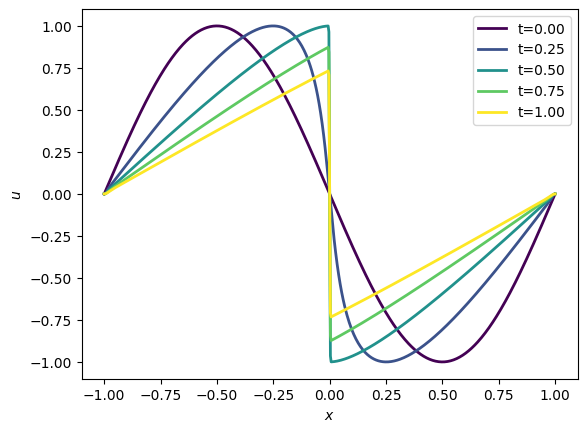

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation

def u0(x):
    return -np.sin(np.pi * x)

def f(u):
    return u ** 2 / 2

def WENO(a, u, dx):
    nx = len(u)
    n_stencil = 3
    I = np.arange(n_stencil-1, nx - n_stencil)

    # Compute the values at the right-hand sides of the cell boundaries (u_{i+1/2}^-) for candidate stencils
    vmm = u[I - 2]
    vm = u[I - 1]
    v = u[I]
    vp = u[I + 1]
    vpp = u[I + 2]

    p0n = (2 * vmm - 7 * vm + 11 * v) / 6
    p1n = (-vm + 5 * v + 2 * vp) / 6
    p2n = (2 * v + 5 * vp - vpp) / 6

    # Compute the weights for candidate stencils
    B0n = 13 / 12 * (vmm - 2 * vm + v) ** 2 + 1 / 4 * (vmm - 4 * vm + 3 * v) ** 2
    B1n = 13 / 12 * (vm - 2 * v + vp) ** 2 + 1 / 4 * (vm - vp) ** 2
    B2n = 13 / 12 * (v - 2 * vp + vpp) ** 2 + 1 / 4 * (3 * v - 4 * vp + vpp) ** 2

    d0n = 1 / 10
    d1n = 6 / 10
    d2n = 3 / 10
    epsilon = 1e-6

    alpha0n = d0n / (epsilon + np.minimum(B0n, 1e30)) ** 2
    alpha1n = d1n / (epsilon + np.minimum(B1n, 1e30)) ** 2
    alpha2n = d2n / (epsilon + np.minimum(B2n, 1e30)) ** 2
    alphasumn = alpha0n + alpha1n + alpha2n

    # ENO stencils weigths
    w0n = alpha0n / alphasumn
    w1n = alpha1n / alphasumn
    w2n = alpha2n / alphasumn

    # Numerical Flux at cell boundary (u_{i+1/2}^{-})
    hn = w0n * p0n + w1n * p1n + w2n * p2n

    # Compute the values at the left-hand side of the cell boundaries (u_{i-1/2}^+)
    vmm = u[I - 1]
    vm = u[I]
    v = u[I + 1]
    vp = u[I + 2]
    vpp = u[I + 3]

    p0p = (-vmm + 5 * vm + 2 * v) / 6
    p1p = (2 * vm + 5 * v - vp) / 6
    p2p = (11 * v - 7 * vp + 2 * vpp) / 6

    B0p = 13 / 12 * (vmm - 2 * vm + v) ** 2 + 1 / 4 * (vmm - 4 * vm + 3 * v) ** 2
    B1p = 13 / 12 * (vm - 2 * v + vp) ** 2 + 1 / 4 * (vm - vp) ** 2
    B2p = 13 / 12 * (v - 2 * vp + vpp) ** 2 + 1 / 4 * (3 * v - 4 * vp + vpp) ** 2

    d0p = 3 / 10
    d1p = 6 / 10
    d2p = 1 / 10
    epsilon = 1e-6

    alpha0p = d0p / (epsilon + np.minimum(B0p, 1e30)) ** 2
    alpha1p = d1p / (epsilon + np.minimum(B1p, 1e30)) ** 2
    alpha2p = d2p / (epsilon + np.minimum(B2p, 1e30)) ** 2
    alphasump = alpha0p + alpha1p + alpha2p

    # ENO stencils weigths
    w0p = alpha0p / alphasump
    w1p = alpha1p / alphasump
    w2p = alpha2p / alphasump

    # Numerical Flux at cell boundary (u_{i-1/2}^{+})
    hp = w0p * p0p + w1p * p1p + w2p * p2p

    LF = np.zeros_like(u)
    res = np.zeros_like(u)

    LF[I] = 0.5 * (f(hn) + f(hp) - abs(a) * (hp - hn)) # Lax-friedrichs flux

    res[I] = (LF[I] - LF[I - 1]) / dx     # L = -df(u) / dx

    return res

if __name__ == "__main__":
    T = 1
    CFL = 0.9
    N = 600
    xl = -1
    xr = 1
    dx = (xr - xl) / N
    nx = N + 1
    x = np.linspace(xl, xr, nx)
    xg = np.concatenate((np.array([xl - 2 * dx, xl - dx]), x, np.array([xr + dx, xr + 2 * dx])))
    nxg = len(xg)

    ut0 = u0(xg)
    lambda0 = max(abs(ut0))
    dt0 = CFL * dx / lambda0
    lbd = lambda0
    dt = dt0
    u = ut0
    t = 0

    solutions = [ut0.copy()]
    times = [0.0]
    iter = 0
    while t < T:
        if t + dt > T: dt = T - t
        t = t + dt

        uo = u
        L = WENO(lbd, u, dx)
        u = uo - dt * L

        u[2] = 0
        u[nxg - 3] = 0
        u[0] = np.interp(xg[0], np.array([xg[2], xg[3], xg[4]]), np.array([u[2], u[3], u[4]]))
        u[1] = np.interp(xg[1], np.array([xg[2], xg[3], xg[4]]), np.array([u[2], u[3], u[4]]))
        u[-1] = np.interp(xg[-1], np.array([xg[nxg-5], xg[nxg-4], xg[nxg-3]]), np.array([u[nxg-5], u[nxg-4], u[nxg-3]]))
        u[-2] = np.interp(xg[-2], np.array([xg[nxg-5], xg[nxg-4], xg[nxg-3]]), np.array([u[nxg-5], u[nxg-4], u[nxg-3]]))

        L = WENO(lbd, u, dx)
        u = 0.75 * uo + 0.25 * (u - dt * L)

        u[2] = 0
        u[nxg - 3] = 0
        u[0] = np.interp(xg[0], np.array([xg[2], xg[3], xg[4]]), np.array([u[2], u[3], u[4]]))
        u[1] = np.interp(xg[1], np.array([xg[2], xg[3], xg[4]]), np.array([u[2], u[3], u[4]]))
        u[-1] = np.interp(xg[-1], np.array([xg[nxg-5], xg[nxg-4], xg[nxg-3]]), np.array([u[nxg-5], u[nxg-4], u[nxg-3]]))
        u[-2] = np.interp(xg[-2], np.array([xg[nxg-5], xg[nxg-4], xg[nxg-3]]), np.array([u[nxg-5], u[nxg-4], u[nxg-3]]))

        L = WENO(lbd, u, dx)
        u = (uo + 2 * (u - dt * L)) / 3

        u[2] = 0
        u[nxg - 3] = 0
        u[0] = np.interp(xg[0], np.array([xg[2], xg[3], xg[4]]), np.array([u[2], u[3], u[4]]))
        u[1] = np.interp(xg[1], np.array([xg[2], xg[3], xg[4]]), np.array([u[2], u[3], u[4]]))
        u[-1] = np.interp(xg[-1], np.array([xg[nxg-5], xg[nxg-4], xg[nxg-3]]), np.array([u[nxg-5], u[nxg-4], u[nxg-3]]))
        u[-2] = np.interp(xg[-2], np.array([xg[nxg-5], xg[nxg-4], xg[nxg-3]]), np.array([u[nxg-5], u[nxg-4], u[nxg-3]]))

        lbd = max(abs(u))
        dt = CFL * dx / lbd

        iter = iter + 1
        solutions.append(u.copy())
        times.append(t)

        # print("current time: t = {}".format(t))

    solutions = np.array(solutions)
    times = np.array(times)

    # Plot and save solutions at approximately every 0.25 seconds
    target_times = np.arange(0, 1.0001, 0.25)
    idxs = [np.argmin(np.abs(times - target)) for target in target_times]
    selected_times = times[idxs]
    selected_solutions = solutions[idxs, 2:nxg-2]

    np.savez('burgers_solutions.npz', times=selected_times, u=solutions[:, 2:nxg-2], x=x)

    fig, ax = plt.subplots()
    colors = plt.cm.viridis(np.linspace(0, 1, len(target_times)))
    for i, idx in enumerate(idxs):
        ax.plot(x, solutions[idx, 2:nxg-2], color=colors[i], label=f't={times[idx]:.2f}', linewidth=2)
    ax.set_xlabel(r'$x$')
    ax.set_ylabel(r'$u$')
    ax.legend()
    plt.savefig('burgers_plot.png')
    plt.show()

current time: t = 0.003
current time: t = 0.006000001652123778
current time: t = 0.009000008246989604
current time: t = 0.012000023075680979
current time: t = 0.015000049430024797
current time: t = 0.018000090573864716
current time: t = 0.021000116925224407
current time: t = 0.02400013177265752
current time: t = 0.02700013840476774
current time: t = 0.030000140110486552
current time: t = 0.03300014017935115
current time: t = 0.03600014190178259
current time: t = 0.039000148569364304
current time: t = 0.04200016347512097
current time: t = 0.04500018991379794
current time: t = 0.0480002310985984
current time: t = 0.05100025750195288
current time: t = 0.05400027240851562
current time: t = 0.0570002791039626
current time: t = 0.0600002808752698
current time: t = 0.0630002810109918
current time: t = 0.06600028280154113
current time: t = 0.06900028953946824
current time: t = 0.07200030451974218
current time: t = 0.07500033104003224
current time: t = 0.07800037226216198
current time: t = 0.08

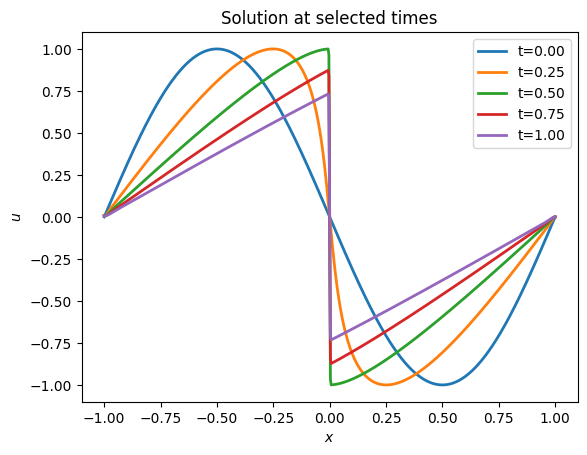

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation

def u0(x):
    return -np.sin(np.pi * x)

def f(u):
    return u ** 2 / 2

def WENO(a, u, dx):
    nx = len(u)
    n_stencil = 3
    I = np.arange(n_stencil-1, nx - n_stencil)

    # Compute the values at the right-hand sides of the cell boundaries (u_{i+1/2}^-) for candidate stencils
    vmm = u[I - 2]
    vm = u[I - 1]
    v = u[I]
    vp = u[I + 1]
    vpp = u[I + 2]

    p0n = (2 * vmm - 7 * vm + 11 * v) / 6
    p1n = (-vm + 5 * v + 2 * vp) / 6
    p2n = (2 * v + 5 * vp - vpp) / 6

    # Compute the weights for candidate stencils
    B0n = 13 / 12 * (vmm - 2 * vm + v) ** 2 + 1 / 4 * (vmm - 4 * vm + 3 * v) ** 2
    B1n = 13 / 12 * (vm - 2 * v + vp) ** 2 + 1 / 4 * (vm - vp) ** 2
    B2n = 13 / 12 * (v - 2 * vp + vpp) ** 2 + 1 / 4 * (3 * v - 4 * vp + vpp) ** 2

    d0n = 1 / 10
    d1n = 6 / 10
    d2n = 3 / 10
    epsilon = 1e-6

    alpha0n = d0n / (epsilon + np.minimum(B0n, 1e30)) ** 2
    alpha1n = d1n / (epsilon + np.minimum(B1n, 1e30)) ** 2
    alpha2n = d2n / (epsilon + np.minimum(B2n, 1e30)) ** 2
    alphasumn = alpha0n + alpha1n + alpha2n

    # ENO stencils weigths
    w0n = alpha0n / alphasumn
    w1n = alpha1n / alphasumn
    w2n = alpha2n / alphasumn

    # Numerical Flux at cell boundary (u_{i+1/2}^{-})
    hn = w0n * p0n + w1n * p1n + w2n * p2n

    # Compute the values at the left-hand side of the cell boundaries (u_{i-1/2}^+)
    vmm = u[I - 1]
    vm = u[I]
    v = u[I + 1]
    vp = u[I + 2]
    vpp = u[I + 3]

    p0p = (-vmm + 5 * vm + 2 * v) / 6
    p1p = (2 * vm + 5 * v - vp) / 6
    p2p = (11 * v - 7 * vp + 2 * vpp) / 6

    B0p = 13 / 12 * (vmm - 2 * vm + v) ** 2 + 1 / 4 * (vmm - 4 * vm + 3 * v) ** 2
    B1p = 13 / 12 * (vm - 2 * v + vp) ** 2 + 1 / 4 * (vm - vp) ** 2
    B2p = 13 / 12 * (v - 2 * vp + vpp) ** 2 + 1 / 4 * (3 * v - 4 * vp + vpp) ** 2

    d0p = 3 / 10
    d1p = 6 / 10
    d2p = 1 / 10
    epsilon = 1e-6

    alpha0p = d0p / (epsilon + np.minimum(B0p, 1e30)) ** 2
    alpha1p = d1p / (epsilon + np.minimum(B1p, 1e30)) ** 2
    alpha2p = d2p / (epsilon + np.minimum(B2p, 1e30)) ** 2
    alphasump = alpha0p + alpha1p + alpha2p

    # ENO stencils weigths
    w0p = alpha0p / alphasump
    w1p = alpha1p / alphasump
    w2p = alpha2p / alphasump

    # Numerical Flux at cell boundary (u_{i-1/2}^{+})
    hp = w0p * p0p + w1p * p1p + w2p * p2p

    LF = np.zeros_like(u)
    res = np.zeros_like(u)

    LF[I] = 0.5 * (f(hn) + f(hp) - abs(a) * (hp - hn)) # Lax-friedrichs flux

    res[I] = (LF[I] - LF[I - 1]) / dx     # L = -df(u) / dx

    return res

if __name__ == "__main__":
    T = 1
    CFL = 0.9
    N = 600
    xl = -1
    xr = 1
    dx = (xr - xl) / N
    nx = N + 1
    x = np.linspace(xl, xr, nx)
    xg = np.concatenate((np.array([xl - 2 * dx, xl - dx]), x, np.array([xr + dx, xr + 2 * dx])))
    nxg = len(xg)

    ut0 = u0(xg)
    lambda0 = max(abs(ut0))
    dt0 = CFL * dx / lambda0
    lbd = lambda0
    dt = dt0
    u = ut0
    t = 0

    res = [ut0.copy()]
    times = [0.0]
    iter = 0
    while t < T:
        if t + dt > T: dt = T - t
        t = t + dt

        uo = u
        L = WENO(lbd, u, dx)
        u = uo - dt * L

        u[0] = np.interp(xg[0], np.array([xg[2], xg[3], xg[4]]), np.array([u[2], u[3], u[4]]))
        u[1] = np.interp(xg[1], np.array([xg[2], xg[3], xg[4]]), np.array([u[2], u[3], u[4]]))
        u[-1] = np.interp(xg[-1], np.array([xg[nxg-5], xg[nxg-4], xg[nxg-3]]), np.array([u[nxg-5], u[nxg-4], u[nxg-3]]))
        u[-2] = np.interp(xg[-2], np.array([xg[nxg-5], xg[nxg-4], xg[nxg-3]]), np.array([u[nxg-5], u[nxg-4], u[nxg-3]]))


        L = WENO(lbd, u, dx)
        u = 0.75 * uo + 0.25 * (u - dt * L)

        u[0] = np.interp(xg[0], np.array([xg[2], xg[3], xg[4]]), np.array([u[2], u[3], u[4]]))
        u[1] = np.interp(xg[1], np.array([xg[2], xg[3], xg[4]]), np.array([u[2], u[3], u[4]]))
        u[-1] = np.interp(xg[-1], np.array([xg[nxg - 5], xg[nxg - 4], xg[nxg - 3]]),
                          np.array([u[nxg - 5], u[nxg - 4], u[nxg - 3]]))
        u[-2] = np.interp(xg[-2], np.array([xg[nxg - 5], xg[nxg - 4], xg[nxg - 3]]),
                          np.array([u[nxg - 5], u[nxg - 4], u[nxg - 3]]))

        L = WENO(lbd, u, dx)
        u = (uo + 2 * (u - dt * L)) / 3

        u[0] = np.interp(xg[0], np.array([xg[2], xg[3], xg[4]]), np.array([u[2], u[3], u[4]]))
        u[1] = np.interp(xg[1], np.array([xg[2], xg[3], xg[4]]), np.array([u[2], u[3], u[4]]))
        u[-1] = np.interp(xg[-1], np.array([xg[nxg - 5], xg[nxg - 4], xg[nxg - 3]]),
                          np.array([u[nxg - 5], u[nxg - 4], u[nxg - 3]]))
        u[-2] = np.interp(xg[-2], np.array([xg[nxg - 5], xg[nxg - 4], xg[nxg - 3]]),
                          np.array([u[nxg - 5], u[nxg - 4], u[nxg - 3]]))


        lbd = max(abs(u))
        dt = CFL * dx / lbd

        res.append(u.copy())
        times.append(t)
        iter = iter + 1

        print("current time: t = {}".format(t))


    res = np.stack(res)

    # Save the solutions (all time steps, excluding ghosts) to a file
    np.savez('burgers_solutions1.npz', times=times, x=x, u=res[:, 2:nxg-2])

    # Plot at t=0, 0.25, 0.5, 0.75, 1.0 (using closest available time steps)
    fig, ax = plt.subplots()
    desired_times = [0.0, 0.25, 0.5, 0.75, 1.0]
    times_array = np.array(times)
    for des in desired_times:
        i = np.argmin(np.abs(times_array - des))
        ax.plot(x, res[i, 2:nxg-2], label=f't={times[i]:.2f}', linewidth=2)
    ax.legend()
    plt.xlabel(r'$x$')
    plt.ylabel(r'$u$')
    plt.title('Solution at selected times')
    plt.savefig('burgers_plot.png')
    plt.show()

Times shape: (5,)
x shape: (601,)
u shape: (314, 601)
Sample times: [0.         0.24900114 0.50100276 0.75140785 1.        ]


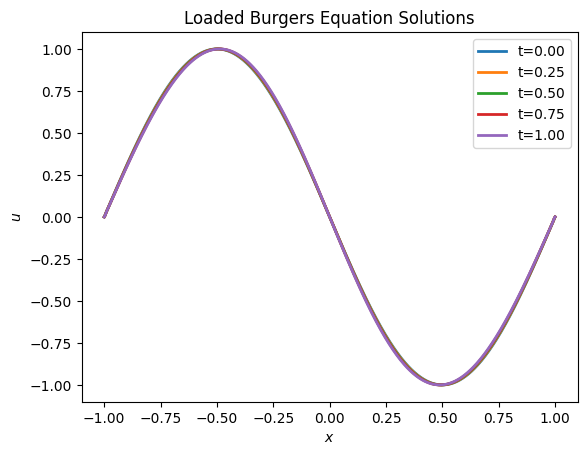

In [24]:
import numpy as np
import matplotlib.pyplot as plt

# Load the .npz file
data = np.load('burgers_solutions.npz')
data1 = np.load('burgers_solutions1.npz')

# Access the arrays
times = data['times']  # Array of time steps
x = data['x']          # Array of spatial points
u = data['u']          # Array of solutions (shape: [n_times, n_x])

# Example: Print the shapes and some values
print("Times shape:", times.shape)
print("x shape:", x.shape)
print("u shape:", u.shape)
print("Sample times:", times[:5])

# Example: Plot solutions at specific times
desired_times = [0.0, 0.25, 0.5, 0.75, 1.0]
fig, ax = plt.subplots()
for des in desired_times:
    i = np.argmin(np.abs(times - des))  # Find index of closest time
    ax.plot(x, u[i], label=f't={times[i]:.2f}', linewidth=2)
ax.legend()
plt.xlabel(r'$x$')
plt.ylabel(r'$u$')
plt.title('Loaded Burgers Equation Solutions')
plt.show()

In [25]:
np.linalg.norm(data['u'] - data1['u'])

np.float64(0.0)

current time: t = 0.001
current time: t = 0.0020000049347697318
current time: t = 0.003000004934826555
current time: t = 0.004000009869539467
current time: t = 0.005000009869653115
current time: t = 0.006000014804309199
current time: t = 0.007000014804479662
current time: t = 0.008000019739078901
current time: t = 0.009000019739306163
current time: t = 0.010000024673848529
current time: t = 0.011000024674132563
current time: t = 0.012000029608618021
current time: t = 0.01300002960895879
current time: t = 0.014000034543387293
current time: t = 0.015000034543784749
current time: t = 0.016000039478156244
current time: t = 0.017000039478610333
current time: t = 0.018000044412924753
current time: t = 0.019000044413435408
current time: t = 0.02000004934769268
current time: t = 0.021000049348259827
current time: t = 0.022000054282459866
current time: t = 0.023000054283083424
current time: t = 0.024000059217226137
current time: t = 0.02500005921790601
current time: t = 0.026000064151991298
cur

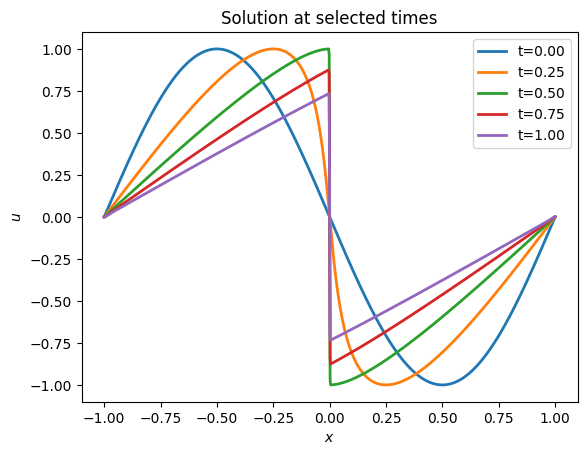

In [29]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation

def u0(x):
    return -np.sin(np.pi * x)

def f(u):
    return u ** 2 / 2

def WENO(a, u, dx):
    nx = len(u)
    n_stencil = 3
    I = np.arange(n_stencil-1, nx - n_stencil)

    # Compute the values at the right-hand sides of the cell boundaries (u_{i+1/2}^-) for candidate stencils
    vmm = u[I - 2]
    vm = u[I - 1]
    v = u[I]
    vp = u[I + 1]
    vpp = u[I + 2]

    p0n = (2 * vmm - 7 * vm + 11 * v) / 6
    p1n = (-vm + 5 * v + 2 * vp) / 6
    p2n = (2 * v + 5 * vp - vpp) / 6

    # Compute the weights for candidate stencils
    B0n = 13 / 12 * (vmm - 2 * vm + v) ** 2 + 1 / 4 * (vmm - 4 * vm + 3 * v) ** 2
    B1n = 13 / 12 * (vm - 2 * v + vp) ** 2 + 1 / 4 * (vm - vp) ** 2
    B2n = 13 / 12 * (v - 2 * vp + vpp) ** 2 + 1 / 4 * (3 * v - 4 * vp + vpp) ** 2

    d0n = 1 / 10
    d1n = 6 / 10
    d2n = 3 / 10
    epsilon = 1e-6

    alpha0n = d0n / (epsilon + np.minimum(B0n, 1e30)) ** 2
    alpha1n = d1n / (epsilon + np.minimum(B1n, 1e30)) ** 2
    alpha2n = d2n / (epsilon + np.minimum(B2n, 1e30)) ** 2
    alphasumn = alpha0n + alpha1n + alpha2n

    # ENO stencils weigths
    w0n = alpha0n / alphasumn
    w1n = alpha1n / alphasumn
    w2n = alpha2n / alphasumn

    # Numerical Flux at cell boundary (u_{i+1/2}^{-})
    hn = w0n * p0n + w1n * p1n + w2n * p2n

    # Compute the values at the left-hand side of the cell boundaries (u_{i-1/2}^+)
    vmm = u[I - 1]
    vm = u[I]
    v = u[I + 1]
    vp = u[I + 2]
    vpp = u[I + 3]

    p0p = (-vmm + 5 * vm + 2 * v) / 6
    p1p = (2 * vm + 5 * v - vp) / 6
    p2p = (11 * v - 7 * vp + 2 * vpp) / 6

    B0p = 13 / 12 * (vmm - 2 * vm + v) ** 2 + 1 / 4 * (vmm - 4 * vm + 3 * v) ** 2
    B1p = 13 / 12 * (vm - 2 * v + vp) ** 2 + 1 / 4 * (vm - vp) ** 2
    B2p = 13 / 12 * (v - 2 * vp + vpp) ** 2 + 1 / 4 * (3 * v - 4 * vp + vpp) ** 2

    d0p = 3 / 10
    d1p = 6 / 10
    d2p = 1 / 10
    epsilon = 1e-6

    alpha0p = d0p / (epsilon + np.minimum(B0p, 1e30)) ** 2
    alpha1p = d1p / (epsilon + np.minimum(B1p, 1e30)) ** 2
    alpha2p = d2p / (epsilon + np.minimum(B2p, 1e30)) ** 2
    alphasump = alpha0p + alpha1p + alpha2p

    # ENO stencils weigths
    w0p = alpha0p / alphasump
    w1p = alpha1p / alphasump
    w2p = alpha2p / alphasump

    # Numerical Flux at cell boundary (u_{i-1/2}^{+})
    hp = w0p * p0p + w1p * p1p + w2p * p2p

    LF = np.zeros_like(u)
    res = np.zeros_like(u)

    LF[I] = 0.5 * (f(hn) + f(hp) - abs(a) * (hp - hn)) # Lax-friedrichs flux

    res[I] = (LF[I] - LF[I - 1]) / dx     # L = -df(u) / dx

    return res

if __name__ == "__main__":
    T = 1
    CFL = 0.5
    N = 1000
    xl = -1
    xr = 1
    dx = (xr - xl) / N
    nx = N + 1
    x = np.linspace(xl, xr, nx)
    xg = np.concatenate((np.array([xl - 2 * dx, xl - dx]), x, np.array([xr + dx, xr + 2 * dx])))
    nxg = len(xg)

    ut0 = u0(xg)
    lambda0 = max(abs(ut0))
    dt0 = CFL * dx / lambda0
    lbd = lambda0
    dt = dt0
    u = ut0
    t = 0

    res = [ut0.copy()]
    times = [0.0]
    iter = 0
    while t < T:
        if t + dt > T: dt = T - t
        t = t + dt
    
        uo = u
        L = WENO(lbd, u, dx)
        u = uo - dt * L
    
        # Enforce Dirichlet BC: set boundary points to 0
        u[2] = 0.0
        u[nxg - 3] = 0.0
        # Set ghost cells to 0 (constant extension for Dirichlet 0)
        u[0] = 0.0
        u[1] = 0.0
        u[-1] = 0.0
        u[-2] = 0.0
    
        L = WENO(lbd, u, dx)
        u = 0.75 * uo + 0.25 * (u - dt * L)
    
        # Enforce again
        u[2] = 0.0
        u[nxg - 3] = 0.0
        u[0] = 0.0
        u[1] = 0.0
        u[-1] = 0.0
        u[-2] = 0.0
    
        L = WENO(lbd, u, dx)
        u = (uo + 2 * (u - dt * L)) / 3
    
        # Enforce again
        u[2] = 0.0
        u[nxg - 3] = 0.0
        u[0] = 0.0
        u[1] = 0.0
        u[-1] = 0.0
        u[-2] = 0.0
    
        lbd = max(abs(u))
        dt = CFL * dx / lbd
    
        res.append(u.copy())
        times.append(t)
        iter = iter + 1
    
        print("current time: t = {}".format(t))

    res = np.stack(res)

    # Save the solutions (all time steps, excluding ghosts) to a file
    np.savez('burgers_sin_ref.npz', times=times, x=x, u=res[:, 2:nxg-2])

    # Plot at t=0, 0.25, 0.5, 0.75, 1.0 (using closest available time steps)
    fig, ax = plt.subplots()
    desired_times = [0.0, 0.25, 0.5, 0.75, 1.0]
    times_array = np.array(times)
    for des in desired_times:
        i = np.argmin(np.abs(times_array - des))
        ax.plot(x, res[i, 2:nxg-2], label=f't={times[i]:.2f}', linewidth=2)
    ax.legend()
    plt.xlabel(r'$x$')
    plt.ylabel(r'$u$')
    plt.title('Solution at selected times')
    plt.savefig('burgers_plot.png')
    plt.show()

In [26]:
np.linspace(-1, 1, 10)

array([-1.        , -0.77777778, -0.55555556, -0.33333333, -0.11111111,
        0.11111111,  0.33333333,  0.55555556,  0.77777778,  1.        ])